#  CNN Notebook CS231

# Design a small, simple custom CNN architecture
The network takes a 224x224x3 RGB input and pass through three Convolutional blocks. Each block consists of a 3x3 Conv2D(stride=1, padding=same) with ReLU activation and MaxPool(2,2) and the number of filters increase from 32->64->128.  The output then gets pooled by AdaptiveAvgPool((2,2)) then the output(128x2x2) get flatten and pass into the classifier with Dropout=0.3 and 512 perceptrons. The classifier outputs 3 classes

## Import library

In [1]:
import csv
from pathlib import Path

import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
CUDA available: True


## Load the StreetSurfaceVis manifest

Use the Kaggle dataset version containing `outputs/manifest_split.csv`, `outputs/preprocessed/`, and `outputs/mapillary_test/`. Training and validation use 2,574 and 644 StreetSurfaceVis images. The test split contains 133 original StreetSurfaceVis images and 34 additional Mapillary images.


In [2]:
manifest_name = "manifest_split.csv"
run_dir = Path("/kaggle/working/street_surface_vis_baseline")

run_dir.mkdir(parents=True, exist_ok=True)
test_output_dir = run_dir / "test_streetsurfacevis_mapillary"
test_output_dir.mkdir(exist_ok=True)

manifest_files = list(
    Path("/kaggle/input").rglob(manifest_name)
)

print("Found:", manifest_files)

if len(manifest_files) != 1:
    raise ValueError(
        f"Expected one {manifest_name}, found {len(manifest_files)}. "
        "Check the paths above."
    )

MANIFEST_PATH = manifest_files[0]
DATA_ROOT = MANIFEST_PATH.parent.parent

print("Manifest:", MANIFEST_PATH)
print("Project directory:", DATA_ROOT)
print("Run directory:", run_dir)

Found: [PosixPath('/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv')]
Manifest: /kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
Project directory: /kaggle/input/datasets/nguyen700/road-types-dataset
Run directory: /kaggle/working/street_surface_vis_baseline


## Check if image paths match the path in manifest

In [3]:
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Manifest not found: {MANIFEST_PATH}")

missing_images = []

with MANIFEST_PATH.open(encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file)

    if "image_path" not in (reader.fieldnames or []):
        raise ValueError("Manifest is missing the image_path column.")

    rows = list(reader)

for row in rows:
    relative_path = row["image_path"].strip()
    image_path = DATA_ROOT / relative_path

    if not relative_path or not image_path.is_file():
        missing_images.append({
            "image_id": row.get("image_id", ""),
            "path": str(image_path),
        })

print("Manifest:", MANIFEST_PATH)
print("Total images:", len(rows))
print("Existing images:", len(rows) - len(missing_images))
print("Missing images:", len(missing_images))

for item in missing_images:
    print("Missing:", item["image_id"], item["path"])

if not rows:
    raise ValueError("Manifest is empty.")

if missing_images:
    raise FileNotFoundError("Fix missing image paths before continuing.")

Manifest: /kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
Total images: 3385
Existing images: 3385
Missing images: 0


## Transform dataset into PyTorch tensors

In [4]:
class TransformRoadDataset(Dataset):
    def __init__(self, manifest_path, data_root, split, transform=None):
        self.data_root = Path(data_root)
        self.transform = transform

        with Path(manifest_path).open(encoding="utf-8", newline="") as file:
            self.rows = [row for row in csv.DictReader(file) if row["split"] == split]

        if not self.rows:
            raise ValueError(f"No sample found in split: {split}")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        image_path = self.data_root / row["image_path"]

        with  Image.open(image_path) as source_image:
            image = source_image.convert("RGB")

        label = torch.tensor(int(row["class_id"]), dtype=torch.long)

        if self.transform is not None:
            image = self.transform(image)

        return image, label  


In [5]:
tensor_transform = transforms.ToTensor()

train_dataset = TransformRoadDataset(
    manifest_path=MANIFEST_PATH,
    data_root=DATA_ROOT,
    split="train",
    transform=tensor_transform,
)

val_dataset = TransformRoadDataset(
    manifest_path=MANIFEST_PATH,
    data_root=DATA_ROOT,
    split="validation",
    transform=tensor_transform,
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))


image, label = train_dataset[0]

print("Image of first sample:", image.shape, image.dtype)
print("Label of first sample:", label.item(), label.dtype)

Train: 2708
Validation: 339
Image of first sample: torch.Size([3, 224, 224]) torch.float32
Label of first sample: 1 torch.int64


## Load the dataset with PyTorch DataLoader


In [6]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False,
)


images, labels = next(iter(train_loader))

print("Images:", images.shape) #Shape is [Number of images, channels, height, width]
print("Labels:", labels.shape) #Shape equal to number of images in batch
print("Label values:", labels)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Label values: tensor([2, 1, 1, 1, 1, 0, 2, 2, 2, 2, 2, 2, 0, 0, 2, 0, 2, 0, 2, 2, 0, 1, 1, 0,
        2, 0, 1, 1, 0, 2, 2, 1])
Train batches: 85
Validation batches: 11


## Show first batch images and labels before training


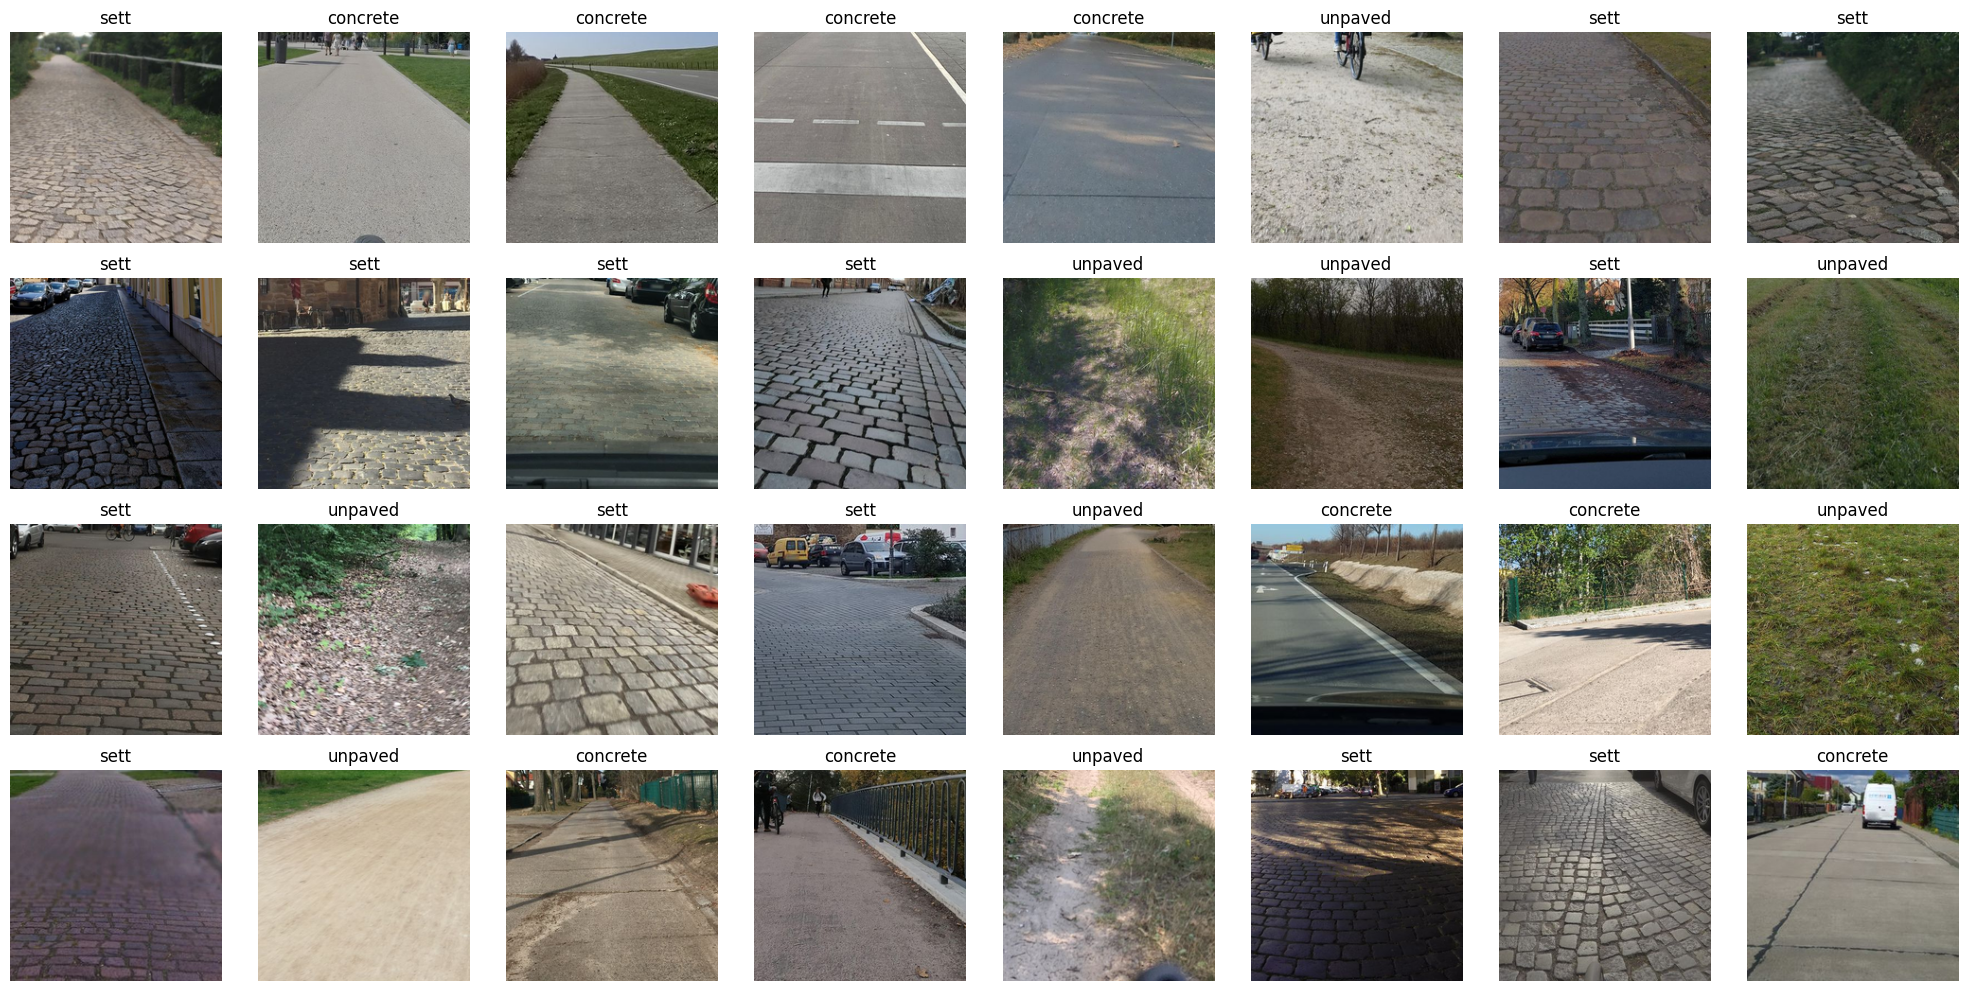

In [7]:
import matplotlib.pyplot as plt

CLASS_NAMES = ("unpaved", "concrete", "sett")

fig, axes = plt.subplots(4, 8, figsize=(20, 10))

for index, ax in enumerate(axes.flat):
    image = images[index].permute(1, 2, 0) #Change dimension to (height, width, channel)

    ax.imshow(image.numpy())
    ax.set_title(CLASS_NAMES[labels[index].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Custom small CNN architecture for image classification

In [8]:
from torch import nn

class SmallCustomCNN(nn.Module):

    def __init__(self, num_classes=3):
        #Init nn.Module
        super().__init__()

        self.features = nn.Sequential(
            #First Conv2D layer input: 3 images channels, output: 32 feature maps
            nn.Conv2d(3, 32, kernel_size=3, padding=1), #Add padding to preserve size
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            #Second Conv2D layer input: 32 feature maps from previous Conv2D layer, output: 64 feature maps
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            #Third Conv2D layer input: 64 feature maps from previous Conv2D layer, output: 128 feature maps
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        #Pool Convolutional layer from 128x28x28 to 128x2x2
        self.pool = nn.AdaptiveAvgPool2d((2,2))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(512, num_classes), #128*2*2 = 512
        )

    def forward(self, images):
        features = self.features(images)
        pooled = self.pool(features)
        logits = self.classifier(pooled)

        return logits

## Evaluate the model (before training) on 1 batch

In [9]:
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_custom = SmallCustomCNN(num_classes=3).to(device)

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

model_custom.eval()

with torch.no_grad():
    logits = model_custom(images)

print("Device:", device)
print("Input:", images.shape)
print("Output:", logits.shape)
print("First image logits:", logits[0])

criterion = nn.CrossEntropyLoss()

loss = criterion(logits, labels)

print("Loss:", loss.item())

Device: cuda
Input: torch.Size([32, 3, 224, 224])
Output: torch.Size([32, 3])
First image logits: tensor([-0.0296,  0.0247,  0.0085], device='cuda:0')
Loss: 1.1010884046554565


## Train on first batch


In [10]:
from torch import nn

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_custom.parameters(), lr=1e-3)

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)
#Turn on train mode
model_custom.train()

optimizer.zero_grad()
logits = model_custom(images) #Predict using current weights
loss = criterion(logits, labels) #Calculate current errors

loss.backward() #Calculate gradients
optimizer.step() #Update weights

predictions = logits.detach().argmax(dim=1) #Choose largest class logit as the prediction
accuracy = (predictions == labels).float().mean().item()

print("Logits shape:", logits.shape)
print("Loss:", loss.item())
print(f"Batch accuracy: {accuracy:.2%}")

Logits shape: torch.Size([32, 3])
Loss: 1.096947193145752
Batch accuracy: 37.50%


## Train function and validation function

In [11]:
def train_on_k_epochs(
    model, loader, criterion, optimizer, device, k_epoch=1, freeze_batch_norm=False,
):
    if k_epoch < 1:
        raise ValueError("k_epoch must be at least 1.")

    history = []

    for epoch in range(k_epoch):
        model.train()
        if freeze_batch_norm:
            for module in model.modules():
                if isinstance(module, nn.BatchNorm2d):
                    module.eval()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            predictions = logits.detach().argmax(dim=1)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

        if total_samples == 0:
            raise ValueError("Training loader yielded no samples.")

        epoch_loss = total_loss / total_samples
        epoch_accuracy = total_correct / total_samples
        history.append({
            "epoch": epoch + 1,
            "train_loss": epoch_loss,
            "train_accuracy": epoch_accuracy,
        })

    return history


In [12]:
from sklearn.metrics import f1_score


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)
            predictions = logits.argmax(dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())

    if total_samples == 0:
        raise ValueError("Evaluation loader yielded no samples.")

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
        "macro_f1": f1_score(
            all_labels,
            all_predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    }

## Reusable classification metrics

In [13]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


def calculate_metrics(true_labels, predicted_labels, class_names):
    if len(true_labels) == 0:
        raise ValueError("No samples to evaluate.")
    if len(true_labels) != len(predicted_labels):
        raise ValueError("Labels and predictions must have equal lengths.")

    class_ids = list(range(len(class_names)))
    if not set(true_labels).issubset(class_ids):
        raise ValueError("Unknown true class ID.")
    if not set(predicted_labels).issubset(class_ids):
        raise ValueError("Unknown predicted class ID.")

    precision, recall, f1, support = precision_recall_fscore_support(
        true_labels, predicted_labels,
        labels=class_ids, average=None, zero_division=0,
    )
    return {
        "accuracy": float(accuracy_score(true_labels, predicted_labels)),
        "macro_f1": float(f1.mean()),
        "macro_precision": float(precision.mean()),
        "macro_recall": float(recall.mean()),
        "per_class": {
            name: {
                "precision": float(precision[i]),
                "recall": float(recall[i]),
                "f1": float(f1[i]),
                "support": int(support[i]),
            }
            for i, name in enumerate(class_names)
        },
    }


def evaluate_classifier(model, loader, device, class_names):
    model.eval()
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            predictions = logits.argmax(dim=1)
            true_labels.extend(labels.cpu().tolist())
            predicted_labels.extend(predictions.cpu().tolist())

    metrics = calculate_metrics(true_labels, predicted_labels, class_names)
    return metrics, true_labels, predicted_labels


## Export confusion matrix as PNG

Rows are predicted classes; columns are true classes. normalize=True divides each column by its true-class support and displays percentages. Classes with zero support have zero columns.

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def save_confusion_matrix_png(
    true_labels,
    predicted_labels,
    class_names,
    output_path,
    title="Confusion matrix",
    show=True,
    normalize=False,
):
    if len(true_labels) == 0:
        raise ValueError("No samples to plot.")
    if len(true_labels) != len(predicted_labels):
        raise ValueError("Labels and predictions must have equal lengths.")
    if not class_names:
        raise ValueError("class_names must not be empty.")

    class_ids = list(range(len(class_names)))
    if not set(true_labels).issubset(class_ids):
        raise ValueError("Unknown true class ID.")
    if not set(predicted_labels).issubset(class_ids):
        raise ValueError("Unknown predicted class ID.")

    output_path = Path(output_path)
    if output_path.suffix.lower() != ".png":
        raise ValueError("output_path must end with .png.")
    output_path.parent.mkdir(parents=True, exist_ok=True)

    # Normalize by true-class support before transposing.
    # Rows represent predictions; columns represent true classes.
    cm = confusion_matrix(
        true_labels, predicted_labels, labels=class_ids,
        normalize="true" if normalize else None,
    ).T

    fig, ax = plt.subplots(figsize=(7, 6))
    try:
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
            ax=ax, cmap="Blues",
            values_format=".1%" if normalize else "d",
            colorbar=False, im_kw={"vmin": 0, "vmax": 1} if normalize else None,
        )
        ax.set_xlabel("Ground truth")
        ax.set_ylabel("Predicted")
        ax.set_title(f"{title} (normalized by true class)" if normalize else title)
        fig.tight_layout()
        fig.savefig(output_path, format="png", dpi=200, bbox_inches="tight")
        if show:
            plt.show()
    finally:
        plt.close(fig)

    return cm


## Train the model

In [15]:
torch.manual_seed(42)

model_custom = SmallCustomCNN(num_classes=3).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_custom.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3,
)

In [16]:
NUM_EPOCHS = 100
PATIENCE = 8

checkpoint_path = run_dir / "best_small_cnn.pt"

history = []
best_macro_f1 = -1.0
epochs_without_improvement = 0

for epoch in range(1, NUM_EPOCHS + 1):
    train_metrics = train_on_k_epochs(
        model=model_custom,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        k_epoch=1,
    )[0]

    val_metrics = evaluate(
        model=model_custom,
        loader=val_loader,
        criterion=criterion,
        device=device,
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_metrics["train_loss"],
        "train_accuracy": train_metrics["train_accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    })
    old_lr = optimizer.param_groups[0]["lr"]

    scheduler.step(val_metrics["loss"])

    new_lr = optimizer.param_groups[0]["lr"]

    if old_lr != new_lr:
        print(f"Learning rate reduced from {old_lr:.6f} to {new_lr:.6f}.")
    print(
        f"Epoch {epoch}/{NUM_EPOCHS} | "
        f"Train loss: {train_metrics['train_loss']:.4f} | "
        f"Train accuracy: {train_metrics['train_accuracy']:.2%} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.2%} | "
        f"Val Macro-F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_macro_f1:
        best_macro_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model_custom.state_dict(),
            "epoch": epoch,
            "val_macro_f1": val_metrics["macro_f1"],
            "class_names": list(CLASS_NAMES),
        }, checkpoint_path)

        print("Saved best checkpoint.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break
    

Epoch 1/100 | Train loss: 1.0477 | Train accuracy: 45.31% | Val loss: 0.9182 | Val accuracy: 54.57% | Val Macro-F1: 0.4223
Saved best checkpoint.
Epoch 2/100 | Train loss: 0.8753 | Train accuracy: 59.71% | Val loss: 0.8293 | Val accuracy: 61.65% | Val Macro-F1: 0.6123
Saved best checkpoint.
Epoch 3/100 | Train loss: 0.7578 | Train accuracy: 67.43% | Val loss: 0.7401 | Val accuracy: 66.67% | Val Macro-F1: 0.6455
Saved best checkpoint.
Epoch 4/100 | Train loss: 0.6819 | Train accuracy: 70.68% | Val loss: 0.7011 | Val accuracy: 69.91% | Val Macro-F1: 0.6875
Saved best checkpoint.
Epoch 5/100 | Train loss: 0.6291 | Train accuracy: 73.56% | Val loss: 0.6860 | Val accuracy: 67.26% | Val Macro-F1: 0.6476
Epoch 6/100 | Train loss: 0.6141 | Train accuracy: 74.22% | Val loss: 0.6608 | Val accuracy: 72.57% | Val Macro-F1: 0.7249
Saved best checkpoint.
Epoch 7/100 | Train loss: 0.5622 | Train accuracy: 77.29% | Val loss: 0.6133 | Val accuracy: 72.27% | Val Macro-F1: 0.7136
Epoch 8/100 | Train loss

## Validation set evaluation

In [17]:
checkpoint_custom = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
if checkpoint_custom["class_names"] != list(CLASS_NAMES):
    raise ValueError("Checkpoint class order does not match CLASS_NAMES.")

model_custom.load_state_dict(checkpoint_custom["model_state_dict"])
print("Validation checkpoint epoch (custom CNN):", checkpoint_custom["epoch"])

val_metrics, val_labels, val_predictions = evaluate_classifier(
    model=model_custom,
    loader=val_loader,
    device=device,
    class_names=CLASS_NAMES,
)

print(f"Val accuracy: {val_metrics['accuracy']:.2%}")
print(f"Val Macro-F1: {val_metrics['macro_f1']:.4f}")
print(f"Val macro precision: {val_metrics['macro_precision']:.4f}")
print(f"Val macro recall: {val_metrics['macro_recall']:.4f}")

for class_name, scores in val_metrics["per_class"].items():
    print(
        f"{class_name}: Precision={scores['precision']:.4f} | "
        f"Recall={scores['recall']:.4f} | F1={scores['f1']:.4f} | "
        f"Support={scores['support']}"
    )

Validation checkpoint epoch (custom CNN): 40
Val accuracy: 84.96%
Val Macro-F1: 0.8484
Val macro precision: 0.8484
Val macro recall: 0.8501
unpaved: Precision=0.8776 | Recall=0.8350 | F1=0.8557 | Support=103
concrete: Precision=0.7890 | Recall=0.8687 | F1=0.8269 | Support=99
sett: Precision=0.8788 | Recall=0.8467 | F1=0.8625 | Support=137


## Final test evaluation

Evaluate the selected checkpoint on the combined StreetSurfaceVis and Mapillary test split.

In [18]:
import json


test_dataset = TransformRoadDataset(
    manifest_path=MANIFEST_PATH,
    data_root=DATA_ROOT,
    split="test",
    transform=tensor_transform,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False,
)

checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=True,
)
if checkpoint["class_names"] != list(CLASS_NAMES):
    raise ValueError("Checkpoint class order does not match CLASS_NAMES.")

model_custom.load_state_dict(checkpoint["model_state_dict"])
model_custom.to(device)

test_metrics, test_labels, test_predictions = evaluate_classifier(
    model=model_custom,
    loader=test_loader,
    device=device,
    class_names=CLASS_NAMES,
)

print("Test samples:", len(test_labels))
print("Checkpoint epoch:", checkpoint["epoch"])
print(f"Test accuracy: {test_metrics['accuracy']:.2%}")
print(f"Test Macro-F1: {test_metrics['macro_f1']:.4f}")
print(f"Test macro precision: {test_metrics['macro_precision']:.4f}")
print(f"Test macro recall: {test_metrics['macro_recall']:.4f}")
for class_name, scores in test_metrics["per_class"].items():
    print(
        f"{class_name}: Precision={scores['precision']:.4f} | "
        f"Recall={scores['recall']:.4f} | F1={scores['f1']:.4f} | "
        f"Support={scores['support']}"
    )

output_dir = test_output_dir
with (output_dir / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump({
        "checkpoint_epoch": checkpoint["epoch"],
        "class_names": list(CLASS_NAMES),
        **test_metrics,
    }, file, indent=2)

# shuffle=False and drop_last=False preserve the dataset row order.
with (output_dir / "test_predictions.csv").open(
    "w", encoding="utf-8", newline=""
) as file:
    writer = csv.writer(file)
    writer.writerow(["image_id", "true_class_id", "predicted_class_id"])
    for row, true_id, predicted_id in zip(
        test_dataset.rows, test_labels, test_predictions
    ):
        writer.writerow([row["image_id"], true_id, predicted_id])


Test samples: 338
Checkpoint epoch: 40
Test accuracy: 89.35%
Test Macro-F1: 0.8904
Test macro precision: 0.8984
Test macro recall: 0.8939
unpaved: Precision=0.9529 | Recall=0.7941 | F1=0.8663 | Support=102
concrete: Precision=0.8033 | Recall=0.9899 | F1=0.8869 | Support=99
sett: Precision=0.9389 | Recall=0.8978 | F1=0.9179 | Support=137


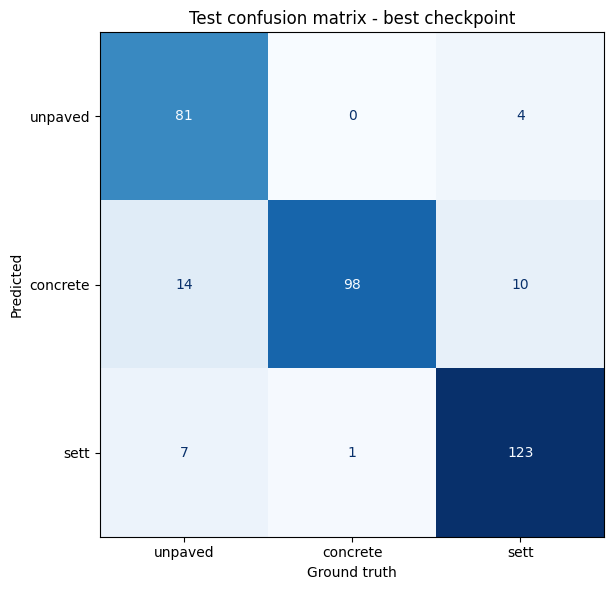

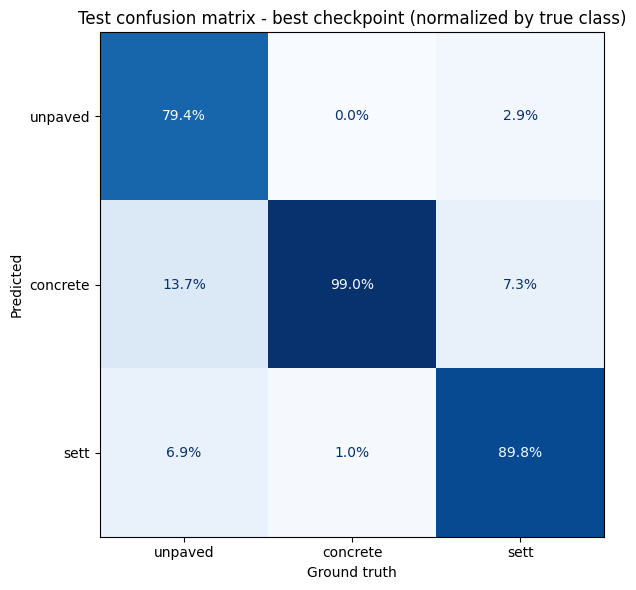

In [19]:
test_cm = save_confusion_matrix_png(
    true_labels=test_labels,
    predicted_labels=test_predictions,
    class_names=CLASS_NAMES,
    output_path=test_output_dir / "test_confusion_matrix.png",
    title="Test confusion matrix - best checkpoint",
)

# Save the normalized version as a separate PNG.
test_cm_normalized = save_confusion_matrix_png(
    true_labels=test_labels,
    predicted_labels=test_predictions,
    class_names=CLASS_NAMES,
    output_path=test_output_dir / "test_confusion_matrix_normalized.png",
    title="Test confusion matrix - best checkpoint",
    normalize=True,
)


# MobileNetV2 Fine-tuning

Train the classifier first, then fine-tune the last two feature modules. Select between the two checkpoints using validation Macro-F1.

## Prepare ImageNet weights and input normalization

In [20]:
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2

weights_mobilenetv2 = MobileNet_V2_Weights.IMAGENET1K_V1
preprocess_mobilenetv2 = weights_mobilenetv2.transforms()
transform_mobilenetv2 = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=preprocess_mobilenetv2.mean, std=preprocess_mobilenetv2.std),
])

train_dataset_mobilenetv2 = TransformRoadDataset(
    MANIFEST_PATH, DATA_ROOT, split="train", transform=transform_mobilenetv2,
)
val_dataset_mobilenetv2 = TransformRoadDataset(
    MANIFEST_PATH, DATA_ROOT, split="validation", transform=transform_mobilenetv2,
)
train_loader_mobilenetv2 = DataLoader(
    train_dataset_mobilenetv2,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
)
val_loader_mobilenetv2 = DataLoader(
    val_dataset_mobilenetv2, batch_size=BATCH_SIZE, shuffle=False,
)


In [21]:
from torch import nn

class ModifiedMobileNetV2(nn.Module):
    def __init__(self, model_mobilenetv2, num_classes):
        super().__init__()
        self.backbone = model_mobilenetv2.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(model_mobilenetv2.classifier[-1].in_features, num_classes),
        )

    def forward(self, images):
        features = self.backbone(images)
        pooled = self.pool(features)
        logits = self.classifier(pooled)
        return logits



## Initialize MobileNetV2 and define the training loop

BatchNorm uses fixed running statistics in both stages. Early stopping and checkpoint selection use validation Macro-F1. The learning rate scheduler tracks validation loss.

In [22]:
torch.manual_seed(42)
model_mobilenetv2_modified = ModifiedMobileNetV2(
    mobilenet_v2(weights=weights_mobilenetv2), num_classes=len(CLASS_NAMES),
).to(device)
model_mobilenetv2_modified.backbone.requires_grad_(False)

criterion_mobilenetv2 = nn.CrossEntropyLoss()
output_dir_mobilenetv2 = run_dir
checkpoint_path_head_mobilenetv2 = output_dir_mobilenetv2 / "mobilenetv2_head.pt"
checkpoint_path_finetune_mobilenetv2 = output_dir_mobilenetv2 / "mobilenetv2_finetune.pt"


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 108MB/s] 


In [23]:
def fit_transfer_stage(
    model, optimizer, checkpoint_path, stage, num_epochs, *,
    train_loader, val_loader, criterion, device, patience=5,
):
    history = []
    best_macro_f1 = -1.0
    epochs_without_improvement = 0
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3,
    )

    for epoch in range(1, num_epochs + 1):
        train_metrics = train_on_k_epochs(
            model, train_loader, criterion, optimizer, device,
            freeze_batch_norm=True,
        )[0]
        val_metrics = evaluate(model, val_loader, criterion, device)

        lr_used = {group["name"]: group["lr"] for group in optimizer.param_groups}
        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["train_loss"],
            "train_accuracy": train_metrics["train_accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "lr": lr_used,
        })
        scheduler.step(val_metrics["loss"])

        print(
            f"{stage} {epoch}/{num_epochs} | Train loss: {train_metrics['train_loss']:.4f} | "
            f"Val loss: {val_metrics['loss']:.4f} | Val accuracy: {val_metrics['accuracy']:.2%} | "
            f"Val Macro-F1: {val_metrics['macro_f1']:.4f} | LR used: {lr_used}"
        )
        if val_metrics["macro_f1"] > best_macro_f1:
            best_macro_f1 = val_metrics["macro_f1"]
            epochs_without_improvement = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "stage": stage,
                "epoch": epoch,
                "val_macro_f1": val_metrics["macro_f1"],
                "class_names": list(CLASS_NAMES),
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping.")
                break

    return history


## Stage 1: Train the classifier head

Freeze the backbone and train the new classifier head on 10 epochs

In [24]:
model_mobilenetv2_modified.backbone.requires_grad_(False)
optimizer_head_mobilenetv2 = torch.optim.Adam([
    {"params": model_mobilenetv2_modified.classifier.parameters(), "lr": 1e-3, "name": "head"},
])
history_head_mobilenetv2 = fit_transfer_stage(
    model_mobilenetv2_modified, optimizer_head_mobilenetv2,
    checkpoint_path_head_mobilenetv2, stage="head", num_epochs=20,
    train_loader=train_loader_mobilenetv2,
    val_loader=val_loader_mobilenetv2,
    criterion=criterion_mobilenetv2,
    device=device,
)


head 1/20 | Train loss: 0.4368 | Val loss: 0.2672 | Val accuracy: 90.27% | Val Macro-F1: 0.8999 | LR used: {'head': 0.001}
head 2/20 | Train loss: 0.2241 | Val loss: 0.2238 | Val accuracy: 92.63% | Val Macro-F1: 0.9231 | LR used: {'head': 0.001}
head 3/20 | Train loss: 0.1942 | Val loss: 0.2001 | Val accuracy: 91.15% | Val Macro-F1: 0.9082 | LR used: {'head': 0.001}
head 4/20 | Train loss: 0.1744 | Val loss: 0.1923 | Val accuracy: 91.45% | Val Macro-F1: 0.9125 | LR used: {'head': 0.001}
head 5/20 | Train loss: 0.1587 | Val loss: 0.1768 | Val accuracy: 92.33% | Val Macro-F1: 0.9205 | LR used: {'head': 0.001}
head 6/20 | Train loss: 0.1542 | Val loss: 0.1712 | Val accuracy: 93.81% | Val Macro-F1: 0.9358 | LR used: {'head': 0.001}
head 7/20 | Train loss: 0.1460 | Val loss: 0.1704 | Val accuracy: 92.33% | Val Macro-F1: 0.9217 | LR used: {'head': 0.001}
head 8/20 | Train loss: 0.1349 | Val loss: 0.1765 | Val accuracy: 92.33% | Val Macro-F1: 0.9214 | LR used: {'head': 0.001}
head 9/20 | Trai

## Stage 2: Fine-tune the final inverted residual block and final convolution
Unfreeze the last two block and train the model

In [25]:
checkpoint_head_mobilenetv2 = torch.load(
    checkpoint_path_head_mobilenetv2, map_location="cpu", weights_only=True,
)
model_mobilenetv2_modified.load_state_dict(checkpoint_head_mobilenetv2["model_state_dict"])
model_mobilenetv2_modified.backbone.requires_grad_(False)
last_layers_mobilenetv2 = model_mobilenetv2_modified.backbone[-2:]
last_layers_mobilenetv2.requires_grad_(True)

optimizer_finetune_mobilenetv2 = torch.optim.Adam([
    {"params": last_layers_mobilenetv2.parameters(), "lr": 1e-5, "name": "backbone"},
    {"params": model_mobilenetv2_modified.classifier.parameters(), "lr": 1e-4, "name": "head"},
])
history_finetune_mobilenetv2 = fit_transfer_stage(
    model_mobilenetv2_modified, optimizer_finetune_mobilenetv2,
    checkpoint_path_finetune_mobilenetv2, stage="fine-tune", num_epochs=30,
    train_loader=train_loader_mobilenetv2,
    val_loader=val_loader_mobilenetv2,
    criterion=criterion_mobilenetv2,
    device=device,
)


fine-tune 1/30 | Train loss: 0.1484 | Val loss: 0.1456 | Val accuracy: 94.40% | Val Macro-F1: 0.9416 | LR used: {'backbone': 1e-05, 'head': 0.0001}
fine-tune 2/30 | Train loss: 0.1172 | Val loss: 0.1541 | Val accuracy: 94.99% | Val Macro-F1: 0.9462 | LR used: {'backbone': 1e-05, 'head': 0.0001}
fine-tune 3/30 | Train loss: 0.1111 | Val loss: 0.1307 | Val accuracy: 94.69% | Val Macro-F1: 0.9449 | LR used: {'backbone': 1e-05, 'head': 0.0001}
fine-tune 4/30 | Train loss: 0.0977 | Val loss: 0.1269 | Val accuracy: 95.58% | Val Macro-F1: 0.9542 | LR used: {'backbone': 1e-05, 'head': 0.0001}
fine-tune 5/30 | Train loss: 0.0909 | Val loss: 0.1249 | Val accuracy: 94.99% | Val Macro-F1: 0.9476 | LR used: {'backbone': 1e-05, 'head': 0.0001}
fine-tune 6/30 | Train loss: 0.0825 | Val loss: 0.1204 | Val accuracy: 96.17% | Val Macro-F1: 0.9600 | LR used: {'backbone': 1e-05, 'head': 0.0001}
fine-tune 7/30 | Train loss: 0.0868 | Val loss: 0.1253 | Val accuracy: 95.87% | Val Macro-F1: 0.9567 | LR used: 

## Validation set evaluation with the selected MobileNetV2 checkpoint

In [26]:
checkpoint_head_mobilenetv2 = torch.load(
    checkpoint_path_head_mobilenetv2, map_location="cpu", weights_only=True,
)
checkpoint_finetune_mobilenetv2 = torch.load(
    checkpoint_path_finetune_mobilenetv2, map_location="cpu", weights_only=True,
)

for result in (checkpoint_head_mobilenetv2, checkpoint_finetune_mobilenetv2):
    if result["class_names"] != list(CLASS_NAMES):  
        raise ValueError("Checkpoint class order does not match CLASS_NAMES.")
    print(f"{result['stage']} epoch {result['epoch']}: Val Macro-F1 {result['val_macro_f1']:.4f}")

# Keep the head-only checkpoint on a tie.
if checkpoint_finetune_mobilenetv2["val_macro_f1"] > checkpoint_head_mobilenetv2["val_macro_f1"]:
    checkpoint_path_mobilenetv2 = checkpoint_path_finetune_mobilenetv2
    selected_checkpoint_mobilenetv2 = checkpoint_finetune_mobilenetv2
else:
    checkpoint_path_mobilenetv2 = checkpoint_path_head_mobilenetv2
    selected_checkpoint_mobilenetv2 = checkpoint_head_mobilenetv2

# Compare validation metrics per class using the best checkpoint of each stage.
for result in (checkpoint_head_mobilenetv2, checkpoint_finetune_mobilenetv2):
    model_mobilenetv2_modified.load_state_dict(result["model_state_dict"])
    stage_metrics, _, _ = evaluate_classifier(
        model_mobilenetv2_modified, val_loader_mobilenetv2, device, CLASS_NAMES,
    )
    per_class_f1 = ", ".join(
        f"{name}={score['f1']:.4f}" for name, score in stage_metrics["per_class"].items()
    )
    print(f"{result['stage']} validation F1: {per_class_f1}")

model_mobilenetv2_modified.load_state_dict(selected_checkpoint_mobilenetv2["model_state_dict"])
print("Selected MobileNetV2 stage:", selected_checkpoint_mobilenetv2["stage"])

val_metrics_mobilenetv2, val_labels_mobilenetv2, val_predictions_mobilenetv2 = evaluate_classifier(
    model=model_mobilenetv2_modified,
    loader=val_loader_mobilenetv2,
    device=device,
    class_names=CLASS_NAMES,
)

print(f"Val accuracy (MobileNetV2): {val_metrics_mobilenetv2['accuracy']:.2%}")
print(f"Val Macro-F1 (MobileNetV2): {val_metrics_mobilenetv2['macro_f1']:.4f}")
print(f"Val macro precision (MobileNetV2): {val_metrics_mobilenetv2['macro_precision']:.4f}")
print(f"Val macro recall (MobileNetV2): {val_metrics_mobilenetv2['macro_recall']:.4f}")

for class_name, scores in val_metrics_mobilenetv2["per_class"].items():
    print(
        f"{class_name}: Precision={scores['precision']:.4f} | "
        f"Recall={scores['recall']:.4f} | F1={scores['f1']:.4f} | "
        f"Support={scores['support']}"
    )

head epoch 6: Val Macro-F1 0.9358
fine-tune epoch 6: Val Macro-F1 0.9600
head validation F1: unpaved=0.9390, concrete=0.9128, sett=0.9556
fine-tune validation F1: unpaved=0.9615, concrete=0.9442, sett=0.9744
Selected MobileNetV2 stage: fine-tune
Val accuracy (MobileNetV2): 96.17%
Val Macro-F1 (MobileNetV2): 0.9600
Val macro precision (MobileNetV2): 0.9598
Val macro recall (MobileNetV2): 0.9604
unpaved: Precision=0.9524 | Recall=0.9709 | F1=0.9615 | Support=103
concrete: Precision=0.9490 | Recall=0.9394 | F1=0.9442 | Support=99
sett: Precision=0.9779 | Recall=0.9708 | F1=0.9744 | Support=137


## Final test on StreetSurfaceVis and Mapillary 

In [27]:
test_dataset_mobilenetv2 = TransformRoadDataset(
    manifest_path=MANIFEST_PATH,
    data_root=DATA_ROOT,
    split="test",
    transform=transform_mobilenetv2,
)

test_loader_mobilenetv2 = DataLoader(
    test_dataset_mobilenetv2,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False,
)

checkpoint_mobilenetv2 = torch.load(
    checkpoint_path_mobilenetv2, map_location="cpu", weights_only=True,
)

if checkpoint_mobilenetv2["class_names"] != list(CLASS_NAMES):
    raise ValueError("Checkpoint class order does not match CLASS_NAMES.")

model_mobilenetv2_modified.load_state_dict(checkpoint_mobilenetv2["model_state_dict"])
model_mobilenetv2_modified.to(device)

test_metrics_mobilenetv2, test_labels_mobilenetv2, test_predictions_mobilenetv2 = evaluate_classifier(
    model=model_mobilenetv2_modified,
    loader=test_loader_mobilenetv2,
    device=device,
    class_names=CLASS_NAMES,
)

print("Test samples (MobileNetV2):", len(test_labels_mobilenetv2))
print("Checkpoint stage (MobileNetV2):", checkpoint_mobilenetv2["stage"])
print("Checkpoint epoch (MobileNetV2):", checkpoint_mobilenetv2["epoch"])
print(f"Test accuracy (MobileNetV2): {test_metrics_mobilenetv2['accuracy']:.2%}")
print(f"Test Macro-F1 (MobileNetV2): {test_metrics_mobilenetv2['macro_f1']:.4f}")
print(f"Test macro precision (MobileNetV2): {test_metrics_mobilenetv2['macro_precision']:.4f}")
print(f"Test macro recall (MobileNetV2): {test_metrics_mobilenetv2['macro_recall']:.4f}")

for class_name, scores in test_metrics_mobilenetv2["per_class"].items():
    print(
        f"{class_name}: Precision={scores['precision']:.4f} | "
        f"Recall={scores['recall']:.4f} | F1={scores['f1']:.4f} | "
        f"Support={scores['support']}"
    )

output_dir_mobilenetv2 = test_output_dir
with (output_dir_mobilenetv2 / "test_metrics_mobilenetv2.json").open("w", encoding="utf-8") as file:
    json.dump({
        "checkpoint_epoch": checkpoint_mobilenetv2["epoch"],
        "checkpoint_stage": checkpoint_mobilenetv2["stage"],
        "class_names": list(CLASS_NAMES),
        **test_metrics_mobilenetv2,
    }, file, indent=2)

with (output_dir_mobilenetv2 / "test_predictions_mobilenetv2.csv").open(
    "w", encoding="utf-8", newline=""
) as file:
    writer = csv.writer(file)
    writer.writerow(["image_id", "true_class_id", "predicted_class_id"])
    for row, true_id, predicted_id in zip(
        test_dataset_mobilenetv2.rows, test_labels_mobilenetv2, test_predictions_mobilenetv2
    ):
        writer.writerow([row["image_id"], true_id, predicted_id])

Test samples (MobileNetV2): 338
Checkpoint stage (MobileNetV2): fine-tune
Checkpoint epoch (MobileNetV2): 6
Test accuracy (MobileNetV2): 96.75%
Test Macro-F1 (MobileNetV2): 0.9655
Test macro precision (MobileNetV2): 0.9659
Test macro recall (MobileNetV2): 0.9659
unpaved: Precision=0.9439 | Recall=0.9902 | F1=0.9665 | Support=102
concrete: Precision=0.9684 | Recall=0.9293 | F1=0.9485 | Support=99
sett: Precision=0.9853 | Recall=0.9781 | F1=0.9817 | Support=137


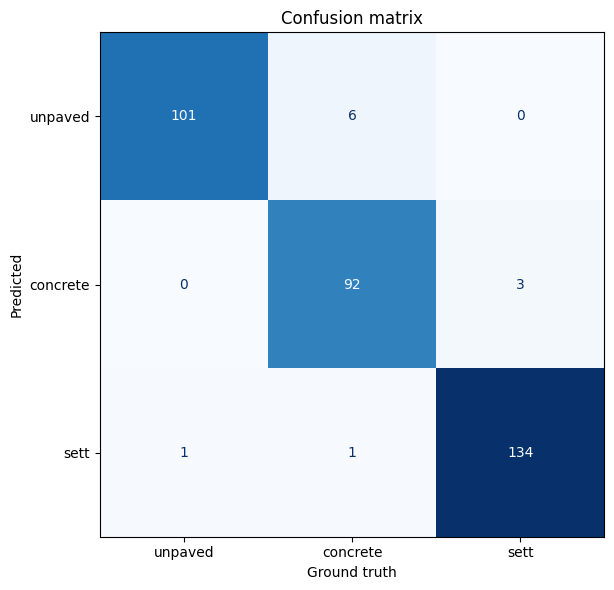

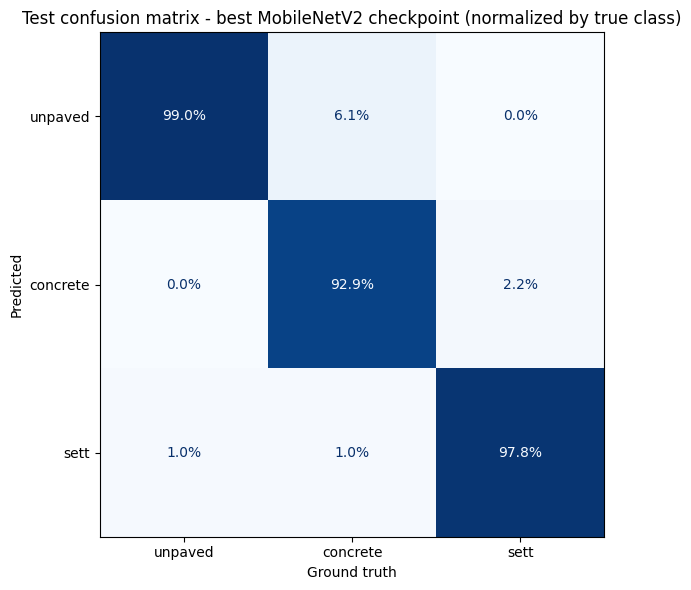

In [28]:
test_cm_mobilenetv2 = save_confusion_matrix_png(
    true_labels=test_labels_mobilenetv2,
    predicted_labels=test_predictions_mobilenetv2,
    class_names=CLASS_NAMES,
    output_path=output_dir_mobilenetv2 / "test_confusion_matrix_mobilenetv2.png"
)

test_cm_normalized_mobilenetv2 = save_confusion_matrix_png(
    true_labels=test_labels_mobilenetv2,
    predicted_labels=test_predictions_mobilenetv2,
    class_names=CLASS_NAMES,
    output_path=output_dir_mobilenetv2 / "test_confusion_matrix_normalized_mobilenetv2.png",
    title="Test confusion matrix - best MobileNetV2 checkpoint",
    normalize=True,
)


## Export misclassified test images by model

Run after both test evaluation cells. Each model gets a ZIP with its own misclassified images and a CSV of true and predicted labels.


In [29]:
import csv
import io
from zipfile import ZIP_DEFLATED, ZipFile


def export_test_errors(rows, true_labels, predictions, data_root, output_path):
    errors = []
    for row, true_id, predicted_id in zip(rows, true_labels, predictions, strict=True):
        if predicted_id != true_id:
            errors.append({
                "image_id": row["image_id"],
                "image_path": row["image_path"],
                "group_id": row.get("group_id", ""),
                "source": row.get("source") or "unknown",
                "true_label": CLASS_NAMES[true_id],
                "predicted_label": CLASS_NAMES[predicted_id],
            })

    report = io.StringIO(newline="")
    writer = csv.DictWriter(report, fieldnames=[
        "image_id", "image_path", "group_id", "source", "true_label", "predicted_label",
    ])
    writer.writeheader()
    writer.writerows(errors)

    with ZipFile(output_path, "w", compression=ZIP_DEFLATED) as archive:
        archive.writestr("predictions.csv", report.getvalue())
        for row in errors:
            source_path = data_root / row["image_path"]
            archive.write(source_path, f"images/{row['image_id']}{source_path.suffix}")

    print(f"Misclassified images: {len(errors)}/{len(rows)}. Saved: {output_path}")


In [30]:
export_test_errors(
    test_dataset.rows, test_labels, test_predictions,
    DATA_ROOT, test_output_dir / "errors_test_custom_cnn.zip",
)
export_test_errors(
    test_dataset_mobilenetv2.rows, test_labels_mobilenetv2, test_predictions_mobilenetv2,
    DATA_ROOT, test_output_dir / "errors_test_mobilenetv2.zip",
)


Misclassified images: 36/338. Saved: /kaggle/working/street_surface_vis_baseline/test_streetsurfacevis_mapillary/errors_test_custom_cnn.zip
Misclassified images: 11/338. Saved: /kaggle/working/street_surface_vis_baseline/test_streetsurfacevis_mapillary/errors_test_mobilenetv2.zip
